In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Merge and General Stat

In [ ]:
# Unzip file in google drive
# import gzip
# import shutil

# gz_path = '/content/drive/MyDrive/419 AI Health Project/MIMIC_III/Data/LABEVENTS.csv.gz'

# # Uncompress the GZ file
# with gzip.open(gz_path, 'rb') as f_in:
#     with open('/content/drive/MyDrive/419 AI Health Project/MIMIC_III/Data/LABEVENTS.csv', 'wb') as f_out:
#         shutil.copyfileobj(f_in, f_out)

In [ ]:
adm = pd.read_csv('/content/drive/MyDrive/419 AI Health/MIMIC_III/Data/ADMISSIONS.csv')
icu_stay = pd.read_csv('/content/drive/MyDrive/419 AI Health/MIMIC_III/Data/ICUSTAYS.csv')
patients = pd.read_csv('/content/drive/MyDrive/419 AI Health/MIMIC_III/Data/PATIENTS.csv')

# Merge useful basic info
icu = icu_stay.drop(columns=['ROW_ID', 'FIRST_CAREUNIT', 'LAST_CAREUNIT', 'FIRST_WARDID', 'LAST_WARDID'])
icu = icu.merge(patients[['SUBJECT_ID', 'GENDER', 'DOB', 'DOD_SSN']], on='SUBJECT_ID')
icu = icu.merge(adm[['HADM_ID', 'ADMITTIME', 'DISCHTIME', 'ADMISSION_TYPE', 'DEATHTIME', 'HOSPITAL_EXPIRE_FLAG', 'HAS_CHARTEVENTS_DATA']], on='HADM_ID')

ICU admission: 61532
Unique patients: 46476
Readmission: 15056
ICU admission without data: 481
ICU admission without stay period date: 10

LOS:
 count    61041.000000
mean         4.931644
std          9.664429
min          0.000100
25%          1.109500
50%          2.094800
75%          4.502200
max        173.072500
Name: LOS, dtype: float64


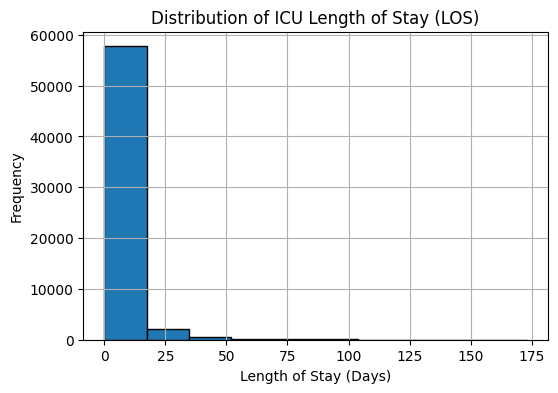

In [ ]:
print("ICU admission:", icu.shape[0])
print("Unique patients:", icu['SUBJECT_ID'].nunique())
print("Readmission:", icu.shape[0] - icu['SUBJECT_ID'].nunique())
print("ICU admission without data:", (icu['HAS_CHARTEVENTS_DATA']==0).sum())
print("ICU admission without stay period date:", icu['OUTTIME'].isnull().sum())

# Exclude stay with incomplete data
icu_basic = icu[(icu['HAS_CHARTEVENTS_DATA']==1) & (icu['OUTTIME'].notnull())]
icu_basic = icu_basic.drop(columns=['HAS_CHARTEVENTS_DATA'])

# Stats of length of stay
print('\nLOS:\n', icu_basic['LOS'].describe())

plt.figure(figsize=(6, 4))
plt.hist(icu_basic['LOS'], bins=10, edgecolor='black')
plt.title('Distribution of ICU Length of Stay (LOS)')
plt.xlabel('Length of Stay (Days)')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

# Filter

In [ ]:
# ICU with LOS>=1 and <=5
icu_basic = icu_basic[(icu_basic['LOS'] >= 1) & (icu_basic['LOS'] <= 5)].reset_index(drop=True)

# Get the masked the age (given formula)
icu_basic['DOB'] = pd.to_datetime(icu_basic['DOB'])
icu_basic['ADMITTIME'] = pd.to_datetime(icu_basic['ADMITTIME'])
icu_basic['AGE'] = (icu_basic['ADMITTIME'].dt.year - icu_basic['DOB'].dt.year).astype(int)
# Ages>89 masked to 300
icu_basic.loc[icu_basic['AGE'] >= 300, 'AGE'] = 90
icu_basic = icu_basic.drop(columns=['DOB'])

# Exclude newborn
print("New-born ICU Admission:", ((icu_basic['ADMISSION_TYPE']=='NEWBORN') | (icu_basic['AGE']==0)).sum())
icu_basic = icu_basic[(icu_basic['ADMISSION_TYPE']!='NEWBORN') & (icu_basic['AGE']!=0) ]


New-born ICU Admission: 1076


In [ ]:
# Out_death = 1 if 'DOD_SSN'-'OUTTIME'<=5: Die in 5 days after discharge of ICU
icu_basic['OUTTIME'] = pd.to_datetime(icu_basic['OUTTIME'])
icu_basic['DOD_SSN'] = pd.to_datetime(icu_basic['DOD_SSN'])
icu_basic['DISCHARGE_EXPIRE'] = np.where(
    (icu_basic['HOSPITAL_EXPIRE_FLAG'] == 0) & (icu_basic['DOD_SSN'].notnull()) &
    ((icu_basic['DOD_SSN'] - icu_basic['OUTTIME']).dt.days <= 5),
    1, 0
)
icu_basic['DEATH'] = icu_basic['HOSPITAL_EXPIRE_FLAG'] + icu_basic['DISCHARGE_EXPIRE']

# Reorder the column name
icu_basic = icu_basic[['SUBJECT_ID', 'HADM_ID', 'ICUSTAY_ID', 'DBSOURCE', 'AGE', 'GENDER', 'LOS', 'INTIME', 'OUTTIME', 'ADMISSION_TYPE', 'ADMITTIME', 'DISCHTIME', 'DEATHTIME', 'HOSPITAL_EXPIRE_FLAG', 'DOD_SSN', 'DISCHARGE_EXPIRE']]
icu_basic.head()

,SUBJECT_ID,HADM_ID,ICUSTAY_ID,DBSOURCE,AGE,GENDER,LOS,INTIME,OUTTIME,ADMISSION_TYPE,ADMITTIME,DISCHTIME,DEATHTIME,HOSPITAL_EXPIRE_FLAG,DOD_SSN,DISCHARGE_EXPIRE
0,268,110404,280836,carevue,66,F,3.2490,2198-02-14 23:27:38,2198-02-18 05:26:11,EMERGENCY,2198-02-11 13:40:00,2198-02-18 03:55:00,2198-02-18 03:55:00,1,NaT,0
1,269,106296,206613,carevue,40,M,3.2788,2170-11-05 11:05:29,2170-11-08 17:46:57,EMERGENCY,2170-11-05 11:04:00,2170-11-27 18:00:00,NaN,0,NaT,0
2,270,188028,220345,carevue,80,M,2.8939,2128-06-24 15:05:20,2128-06-27 12:32:29,ELECTIVE,2128-06-23 18:26:00,2128-06-27 12:31:00,NaN,0,NaT,0
3,271,173727,249196,carevue,46,F,2.0600,2120-08-07 23:12:42,2120-08-10 00:39:04,EMERGENCY,2120-08-07 18:56:00,2120-08-20 16:00:00,NaN,0,NaT,0
4,272,164716,210407,carevue,67,M,1.6202,2186-12-25 21:08:04,2186-12-27 12:01:13,EMERGENCY,2186-12-25 21:06:00,2187-01-02 14:57:00,NaN,0,NaT,0


ICU admission: 33998
Unique patients: 27056
Readmission: 6942
In-hospitial death: 3020
Discharge death: 174
Total death: 3194


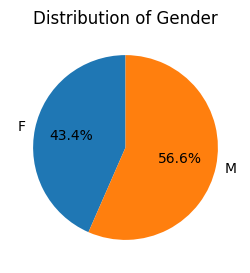

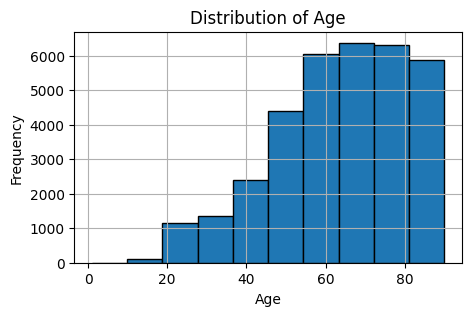

In [ ]:
# Basic statistics after filtering
print("ICU admission:", icu_basic.shape[0])
print("Unique patients:", icu_basic['SUBJECT_ID'].nunique())
print("Readmission:", icu_basic.shape[0] - icu_basic['SUBJECT_ID'].nunique())
print("In-hospitial death:", icu_basic['HOSPITAL_EXPIRE_FLAG'].sum())
print("Discharge death:", icu_basic['DISCHARGE_EXPIRE'].sum())
print("Total death:", icu_basic['HOSPITAL_EXPIRE_FLAG'].sum() + icu_basic['DISCHARGE_EXPIRE'].sum())

# Gender Distribution
plt.figure(figsize=(3, 3))
gender_counts = icu_basic['GENDER'].value_counts().sort_index()
plt.pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Distribution of Gender')

# Age Distribution
plt.figure(figsize=(5, 3))
plt.hist(icu_basic['AGE'], bins=10, edgecolor='black')
plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

In [ ]:
#icu_basic.to_csv("/content/drive/MyDrive/419 AI Health/MIMIC_III/Resources/A_ICU_Info.csv", index=False)